# Hands-on 23 (Bab 9): Membandingkan Threshold Statis vs Model Anomaly Detection

Buku Referensi: *IoT Terintegrasi dengan Machine Learning & Data Analytics* (Onno W. Purbo), Bab 9.

Dua pendekatan umum IoT dibandingkan terhadap ground truth: threshold statis
(current > 10 A) dan Isolation Forest. Tujuannya memahami kapan threshold cukup
dan kapan model ML memberi nilai tambah.

In [1]:
import os
from pathlib import Path

while not (Path.cwd() / "scripts" / "mqtt").is_dir():
    os.chdir("..")
print("[INFO] Working directory:", Path.cwd())

[INFO] Working directory: /home/sandbox/iot-ml-book


## 1. Threshold Statis

In [2]:
import subprocess, sys
r = subprocess.run([sys.executable, "scripts/current_threshold_detection.py"], capture_output=True, text=True)
print(r.stdout)

=== Threshold Detection ===
threshold_anomaly
0    485
1     15
Name: count, dtype: int64

Confusion Matrix:
[[485   0]
 [  0  15]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       485
           1       1.00      1.00      1.00        15

    accuracy                           1.00       500
   macro avg       1.00      1.00      1.00       500
weighted avg       1.00      1.00      1.00       500




## 2. Perbandingan Metrik

In [3]:
r = subprocess.run([sys.executable, "scripts/compare_threshold_vs_iforest.py"], capture_output=True, text=True)
print(r.stdout)

=== Perbandingan Threshold vs Isolation Forest ===
            method  accuracy  precision  recall   f1
0        Threshold       1.0        1.0     1.0  1.0
1  IsolationForest       1.0        1.0     1.0  1.0



## 3. Visualisasi F1 dan Recall

Figure(800x500)
Figure(800x500)



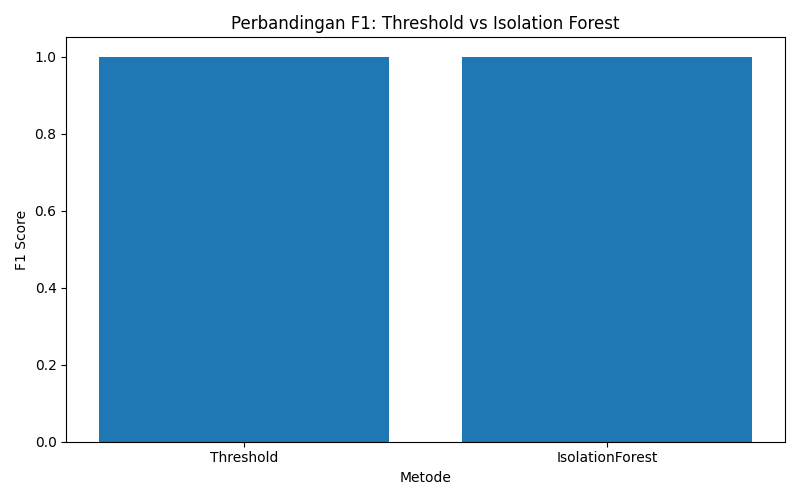

In [4]:
r = subprocess.run([sys.executable, "scripts/plot_threshold_vs_iforest.py"], capture_output=True, text=True)
print(r.stdout)
from IPython.display import Image
Image("outputs/figures/threshold_vs_iforest_f1.png")

## Penutup

Pada dataset ini kedua metode sama-sama sempurna (F1 = 1.00) karena anomali buatan
berupa lonjakan 4-8 A sangat jelas dari satu ambang. Pada data nyata anomali lebih
halus: threshold cocok untuk alarm cepat yang sangat jelas, Isolation Forest untuk
pola multivariat yang halus, dan kombinasi keduanya sering paling masuk akal.
Hasil tersimpan di `outputs/reports/threshold_vs_iforest.csv`.

## Catatan dari buku: pengamatan, variasi, dan latihan

Bagian berikut disalin dari buku (Hands-on 25 dalam urutan buku) sebagai panduan pengamatan dan latihan mandiri setelah menjalankan notebook ini.

### 8. Langkah kerja yang harus dilakukan pembaca

Tahap 1
Siapkan data sensor yang cukup bersih.
Tahap 2
Mulai dari pendekatan paling sederhana:
- threshold statis
Tahap 3
Bangun model anomaly detection:
- Isolation Forest
Tahap 4
Bandingkan hasilnya terhadap:
- ground truth sintetis
- atau verifikasi visual/domain knowledge bila data nyata
Tahap 5
Lihat metrik:

precision
recall
F1
confusion matrix

Tahap 6
Putuskan strategi operasional:
- threshold saja
- model saja
- atau kombinasi keduanya

## Jawaban dari data: Strategi operasional (Hands-on 23): jawaban dari data

In [5]:
import pandas as pd
r = pd.read_csv("outputs/reports/threshold_vs_iforest.csv")
print(r.to_string(index=False))
best = r.sort_values("f1", ascending=False).iloc[0]
print(f"Metode dengan F1 tertinggi: {best['method']} (F1={best['f1']:.3f}). Jika semua metode sama baik pada data sintetis, threshold sederhana sudah cukup; model atau kombinasi layak dipakai bila pola anomali tidak lagi sederhana.")

         method  accuracy  precision  recall  f1
      Threshold       1.0        1.0     1.0 1.0
IsolationForest       1.0        1.0     1.0 1.0
Metode dengan F1 tertinggi: Threshold (F1=1.000). Jika semua metode sama baik pada data sintetis, threshold sederhana sudah cukup; model atau kombinasi layak dipakai bila pola anomali tidak lagi sederhana.
